In [ ]:
# Retail Inventory Data Analysis

import pandas as pd
import matplotlib.pyplot as plt

data = {
    "Product": [
        "Laptop",
        "Mouse",
        "Keyboard",
        "Monitor",
        "Webcam",
        "Laptop",
        "Headset"
    ],
    "Price": [
        1200,
        150,
        250,
        450,
        None,
        1200,
        100
    ],
    "Quantity": [
        5,
        12,
        8,
        4,
        6,
        5,
        None
    ]
}

df_assessment = pd.DataFrame(data)

print(df_assessment)

# Check for Missing Values
print(df_assessment.isnull().sum())




    Product   Price  Quantity
0    Laptop  1200.0       5.0
1     Mouse   150.0      12.0
2  Keyboard   250.0       8.0
3   Monitor   450.0       4.0
4    Webcam     NaN       6.0
5    Laptop  1200.0       5.0
6   Headset   100.0       NaN
Product     0
Price       1
Quantity    1
dtype: int64


In [ ]:
# Step 2: Create a Working Copy

df_clean = df_assessment.copy()
print(df_clean)

    Product   Price  Quantity
0    Laptop  1200.0       5.0
1     Mouse   150.0      12.0
2  Keyboard   250.0       8.0
3   Monitor   450.0       4.0
4    Webcam     NaN       6.0
5    Laptop  1200.0       5.0
6   Headset   100.0       NaN


In [ ]:

#3 Fill Missing Prices Using the Median

median_price = df_clean["Price"].median()

df_clean["Price"] = df_clean["Price"].fillna(median_price)
print("Median Price:", median_price)
print(df_clean)


# Fill Missing Quantities Using the Median

median_quantity = df_clean["Quantity"].median()
df_clean["Quantity"] = df_clean["Quantity"].fillna(median_quantity)
print("Median Quantity:", median_quantity)
print(df_clean)



Median Price: 350.0
    Product   Price  Quantity
0    Laptop  1200.0       5.0
1     Mouse   150.0      12.0
2  Keyboard   250.0       8.0
3   Monitor   450.0       4.0
4    Webcam   350.0       6.0
5    Laptop  1200.0       5.0
6   Headset   100.0       NaN
Median Quantity: 5.5
    Product   Price  Quantity
0    Laptop  1200.0       5.0
1     Mouse   150.0      12.0
2  Keyboard   250.0       8.0
3   Monitor   450.0       4.0
4    Webcam   350.0       6.0
5    Laptop  1200.0       5.0
6   Headset   100.0       5.5


In [12]:

# Verify Missing Values Have Been Handled

print(df_clean.isnull().sum())


Product     0
Price       0
Quantity    0
dtype: int64


In [13]:

# Step 4: Identify Duplicate Records

print(df_clean.duplicated())
print("\nTotal Duplicate Rows:", df_clean.duplicated().sum())


0    False
1    False
2    False
3    False
4    False
5     True
6    False
dtype: bool

Total Duplicate Rows: 1


In [14]:

# Step 5: Remove Duplicate Records

df_final = df_clean.drop_duplicates()

print(df_final)


    Product   Price  Quantity
0    Laptop  1200.0       5.0
1     Mouse   150.0      12.0
2  Keyboard   250.0       8.0
3   Monitor   450.0       4.0
4    Webcam   350.0       6.0
6   Headset   100.0       5.5


In [15]:

#6 Reset the Index

df_final = df_final.reset_index(drop=True)

print(df_final)


    Product   Price  Quantity
0    Laptop  1200.0       5.0
1     Mouse   150.0      12.0
2  Keyboard   250.0       8.0
3   Monitor   450.0       4.0
4    Webcam   350.0       6.0
5   Headset   100.0       5.5


In [ ]:
# Calculate revenue for each product (Price × Quantity)
revenue_per_product = df_final["Price"] * df_final["Quantity"]
df_final["Revenue"] = revenue_per_product
print(df_final)

    Product   Price  Quantity  Revenue
0    Laptop  1200.0       5.0   6000.0
1     Mouse   150.0      12.0   1800.0
2  Keyboard   250.0       8.0   2000.0
3   Monitor   450.0       4.0   1800.0
4    Webcam   350.0       6.0   2100.0
5   Headset   100.0       5.5    550.0


In [17]:
# total revenue

total_revenue = df_final["Revenue"].sum()
print("Total Revenue:", total_revenue)

Total Revenue: 14250.0


In [18]:
# total quantity

total_quantity = df_final["Quantity"].sum()
print("Total Quantity:", total_quantity)

Total Quantity: 40.5


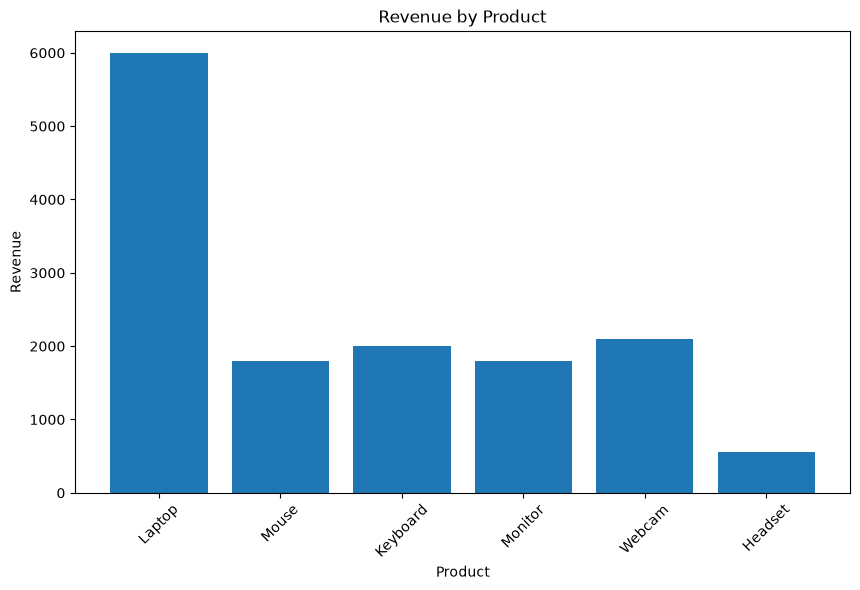

In [19]:
# Create a bar chart showing revenue by product
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.bar(df_final["Product"], df_final["Revenue"])
plt.xlabel("Product")
plt.ylabel("Revenue")
plt.title("Revenue by Product")
plt.xticks(rotation=45)
plt.show()

In [20]:

# Reset the Index

df_final = df_final.reset_index(drop=True)

print(df_final)


    Product   Price  Quantity  Revenue
0    Laptop  1200.0       5.0   6000.0
1     Mouse   150.0      12.0   1800.0
2  Keyboard   250.0       8.0   2000.0
3   Monitor   450.0       4.0   1800.0
4    Webcam   350.0       6.0   2100.0
5   Headset   100.0       5.5    550.0


In [21]:

# Validate the Final Dataset

print("Total Records:", len(df_final))
print("Missing Values:", df_final.isnull().sum().sum())
print("Duplicate Rows:", df_final.duplicated().sum())


Total Records: 6
Missing Values: 0
Duplicate Rows: 0
